**phase1: loading datasets**


In [8]:
import pandas as pd
import numpy as np
from pathlib import Path


In [10]:
DATA_DIR = Path("../data/raw")

orders = pd.read_csv(
    DATA_DIR / "orders.csv",
    parse_dates=["order_date"]
)

order_items = pd.read_csv(
    DATA_DIR / "order_items.csv"
)

products = pd.read_csv(
    DATA_DIR / "products.csv"
)

customers = pd.read_csv(
    DATA_DIR / "customers.csv",
    parse_dates=["signup_date"]
)

In [11]:
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)

Orders: (9245, 7)
Order Items: (15608, 5)
Products: (90, 5)
Customers: (3600, 4)


**Phase 2: Inspect The Data**

1. Checking the column names

In [26]:
print("ORDERS")
print(orders.columns.tolist())

print("\nORDER ITEMS")
print(order_items.columns.tolist())

print("\nPRODUCTS")
print(products.columns.tolist())

print("\nCUSTOMERS")
print(customers.columns.tolist())

ORDERS
['order_id', 'customer_id', 'order_date', 'status', 'payment_method', 'discount_code', 'shipping_fee']

ORDER ITEMS
['order_id', 'product_id', 'quantity', 'unit_price', 'discount_amount']

PRODUCTS
['product_id', 'product_name', 'category', 'list_price', 'unit_cost']

CUSTOMERS
['customer_id', 'signup_date', 'state', 'acquisition_channel']


2. Checking the data types

In [13]:
print("ORDERS")
orders.info()

print("\nORDER ITEMS")
order_items.info()

print("\nPRODUCTS")
products.info()

print("\nCUSTOMERS")
customers.info()

ORDERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9245 entries, 0 to 9244
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        9245 non-null   int64         
 1   customer_id     9245 non-null   int64         
 2   order_date      9245 non-null   datetime64[ns]
 3   status          9245 non-null   object        
 4   payment_method  9245 non-null   object        
 5   discount_code   1411 non-null   object        
 6   shipping_fee    9245 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(3)
memory usage: 505.7+ KB

ORDER ITEMS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15608 entries, 0 to 15607
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         15608 non-null  int64  
 1   product_id       15608 non-null  int64  
 2   quantity         15608 non

Step 3: Calculating missing values for every dataset

In [14]:
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Customers": customers
}

for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isnull().sum())


Orders
order_id             0
customer_id          0
order_date           0
status               0
payment_method       0
discount_code     7834
shipping_fee         0
dtype: int64

Order Items
order_id             0
product_id           0
quantity             0
unit_price         199
discount_amount      0
dtype: int64

Products
product_id      0
product_name    0
category        0
list_price      0
unit_cost       0
dtype: int64

Customers
customer_id            0
signup_date            0
state                  0
acquisition_channel    0
dtype: int64


Step 4: checking the missing unit_price values

In [17]:
missing_price = order_items[order_items["unit_price"].isnull()]
print('Rows with missing unit_price:', len(missing_price))
missing_price.head(10)

Rows with missing unit_price: 199


,order_id,product_id,quantity,unit_price,discount_amount
55,100033,1086,1,NaN,0.0
110,100062,1020,1,NaN,0.0
197,100116,1087,2,NaN,0.0
366,100210,1014,1,NaN,0.0
626,100361,1077,1,NaN,0.0
685,100396,1015,1,NaN,0.0
822,100468,1004,2,NaN,0.0
958,100545,1090,2,NaN,0.0
1007,100573,1090,1,NaN,0.0
1125,100639,1087,2,NaN,0.0


Step 5: Display the missing-price rows clearly

In [27]:
missing_price = order_items[order_items["unit_price"].isna()]

print(missing_price[[
    "order_id",
    "product_id",
    "quantity",
    "unit_price",
    "discount_amount"
]].head(10).to_string(index=False))

 order_id  product_id  quantity  unit_price  discount_amount
   100033        1086         1         NaN              0.0
   100062        1020         1         NaN              0.0
   100116        1087         2         NaN              0.0
   100210        1014         1         NaN              0.0
   100361        1077         1         NaN              0.0
   100396        1015         1         NaN              0.0
   100468        1004         2         NaN              0.0
   100545        1090         2         NaN              0.0
   100573        1090         1         NaN              0.0
   100639        1087         2         NaN              0.0


Step 6: Checking whether those products exist

In [18]:
missing_product_ids = missing_price["product_id"].unique()

product_details = products[
    products["product_id"].isin(missing_product_ids)
][["product_id", "product_name", "category", "list_price", "unit_cost"]]

product_details.head(10)

,product_id,product_name,category,list_price,unit_cost
0,1001,Brass Chef Knife,Kitchen,61.99,38.13
1,1002,Walnut Cutting Board,Kitchen,138.99,74.76
2,1003,Matte Black Dutch Oven,Kitchen,22.99,13.50
3,1004,Classic Skillet,Kitchen,75.99,39.86
4,1005,Linen Mixing Bowl Set,Kitchen,79.99,41.11
5,1006,Walnut Coffee Grinder,Kitchen,16.99,9.74
6,1007,Modern Spice Rack,Kitchen,71.99,37.72
7,1008,Matte Black Utensil Set,Kitchen,43.99,19.06
8,1009,Brass Baking Sheet,Kitchen,131.99,76.08
9,1010,Marble Tea Kettle,Kitchen,96.99,42.68


Step 7: Checking how many missing-price rows have matching products

In [19]:
print("Missing-price rows:", len(missing_price))
print("Distinct affected products:", missing_price["product_id"].nunique())

print(
    "Affected products found in products dataset:",
    missing_price["product_id"].isin(products["product_id"]).sum()
)

Missing-price rows: 199
Distinct affected products: 78
Affected products found in products dataset: 199


Step 8: Checking whether missing prices can be recovered

In [20]:
# Select order items where the transaction price is available
available_prices = order_items.dropna(subset=["unit_price"])

# Calculate the number of distinct recorded prices for each product
price_variation = (
    available_prices.groupby("product_id")["unit_price"]
    .nunique()
    .reset_index(name="distinct_prices")
)

# Find products with missing prices
affected_products = missing_price[["product_id"]].drop_duplicates()

# Check price variation for affected products
affected_price_check = affected_products.merge(
    price_variation,
    on="product_id",
    how="left"
)

affected_price_check.head(10)

,product_id,distinct_prices
0,1086,2
1,1020,2
2,1087,2
3,1014,2
4,1077,2
5,1015,2
6,1004,2
7,1090,2
8,1037,2
9,1041,2


Step 9: Checking whether the products have consistent prices

In [21]:
# Calculate minimum, maximum, and average recorded price for each product
product_price_summary = (
    order_items.dropna(subset=["unit_price"])
    .groupby("product_id")["unit_price"]
    .agg(["min", "max", "mean", "nunique"])
    .reset_index()
)

# Select products affected by missing prices
affected_price_summary = affected_products.merge(
    product_price_summary,
    on="product_id",
    how="left"
)

# Add product list prices
affected_price_summary = affected_price_summary.merge(
    products[["product_id", "product_name", "list_price"]],
    on="product_id",
    how="left"
)

affected_price_summary.head(10)

,product_id,min,max,mean,nunique,product_name,list_price
0,1086,97.99,102.89,100.858293,2,Modern Under Bed Bin,97.99
1,1020,54.99,57.74,56.407702,2,Coastal Weighted Blanket,54.99
2,1087,45.99,48.29,47.129823,2,Cotton Pantry Container Set,45.99
3,1014,36.99,38.84,37.863869,2,Matte Black Stock Pot,36.99
4,1077,25.99,27.29,26.687021,2,Classic Table Runner,25.99
5,1015,96.99,101.84,99.579593,2,Oak Measuring Cup Set,96.99
6,1004,75.99,79.79,78.138691,2,Classic Skillet,75.99
7,1090,17.99,18.89,18.450664,2,Bamboo Laundry Basket,17.99
8,1037,28.99,30.44,29.854912,2,Coastal Waffle Towel Set,28.99
9,1041,553.99,581.69,567.005663,2,Nordic Side Table,553.99


**3. Document the missing values**

In [22]:
cleaning_log = pd.DataFrame([
    {
        "dataset": "orders",
        "column": "discount_code",
        "issue": "Missing values",
        "count": orders["discount_code"].isna().sum(),
        "decision": "Retain missing values; they may indicate no discount code was used"
    },
    {
        "dataset": "order_items",
        "column": "unit_price",
        "issue": "Missing transaction prices",
        "count": order_items["unit_price"].isna().sum(),
        "decision": "Retain missing values; exclude from revenue calculations unless reliably recovered"
    }
])

cleaning_log

,dataset,column,issue,count,decision
0,orders,discount_code,Missing values,7834,Retain missing values; they may indicate no di...
1,order_items,unit_price,Missing transaction prices,199,Retain missing values; exclude from revenue ca...


**4. Next: Check for duplicate records**

In [23]:
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Customers": customers
}

for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

Orders: 38 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Customers: 0 duplicate rows


In [24]:
orders[orders.duplicated(keep=False)].head(10)

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
47,100048,3320,2024-01-06 16:37:36,completed,credit_card,NaN,6.95
130,107012,870,2025-08-12 10:39:49,completed,apple_pay,NaN,0.00
303,100303,853,2024-02-03 08:33:22,completed,apple_pay,NaN,0.00
310,106199,3072,2025-06-09 23:50:03,completed,credit_card,NaN,6.95
479,104695,443,2025-02-14 11:56:23,completed,credit_card,NaN,0.00
712,100710,526,2024-03-13 13:39:17,completed,credit_card,NaN,0.00
781,100779,1209,2024-03-20 11:07:55,completed,gift_card,NaN,0.00
1245,104455,3069,2025-01-24 08:19:45,completed,credit_card,NaN,0.00
1383,101380,2821,2024-05-15 16:28:12,completed,credit_card,NaN,0.00
1493,104239,2580,2025-01-03 17:03:06,completed,credit_card,NaN,0.00


In [25]:
print("Original number of order rows:", len(orders))
print("Exact duplicate rows:", orders.duplicated().sum())
print("Rows involved in duplicates:", orders.duplicated(keep=False).sum())

Original number of order rows: 9245
Exact duplicate rows: 38
Rows involved in duplicates: 76


In [28]:
# Remove exact duplicate rows
orders = orders.drop_duplicates()

# Verify the result
print("Rows after cleaning:", len(orders))
print("Remaining duplicate rows:", orders.duplicated().sum())

Rows after cleaning: 9207
Remaining duplicate rows: 0


In [29]:
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Duplicate product IDs:", products["product_id"].duplicated().sum())
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())

Duplicate order IDs: 0
Duplicate product IDs: 0
Duplicate customer IDs: 0


checking numerical values

In [30]:
print("Orders: negative shipping fees")
print((orders["shipping_fee"] < 0).sum())

print("\nOrder Items: zero or negative quantities")
print((order_items["quantity"] <= 0).sum())

print("\nOrder Items: negative unit prices")
print((order_items["unit_price"] < 0).sum())

print("\nOrder Items: negative discount amounts")
print((order_items["discount_amount"] < 0).sum())

print("\nProducts: non-positive list prices")
print((products["list_price"] <= 0).sum())

print("\nProducts: negative unit costs")
print((products["unit_cost"] < 0).sum())

Orders: negative shipping fees
0

Order Items: zero or negative quantities
0

Order Items: negative unit prices
0

Order Items: negative discount amounts
0

Products: non-positive list prices
0

Products: negative unit costs
0


 Checking category and status values

In [31]:
print("Order statuses:")
print(orders["status"].value_counts(dropna=False))

print("\nPayment methods:")
print(orders["payment_method"].value_counts(dropna=False))

print("\nProduct categories:")
print(products["category"].value_counts(dropna=False))

print("\nCustomer acquisition channels:")
print(customers["acquisition_channel"].value_counts(dropna=False))

Order statuses:
status
completed    8456
returned      407
canceled      344
Name: count, dtype: int64

Payment methods:
payment_method
credit_card    5310
paypal         1955
apple_pay      1413
gift_card       529
Name: count, dtype: int64

Product categories:
category
Kitchen       10
Furniture      9
Outdoor        9
Bath           9
Decor          8
Bedding        8
Lighting       8
Storage        7
decor          4
 Kitchen       2
Storage        2
 Bedding       2
bath           1
BEDDING        1
furniture      1
FURNITURE      1
bedding        1
LIGHTING       1
OUTDOOR        1
 Outdoor       1
KITCHEN        1
kitchen        1
Kitchen        1
Furniture      1
Name: count, dtype: int64

Customer acquisition channels:
acquisition_channel
organic_search    1230
paid_social        831
paid_search        550
email              423
referral           367
affiliate          199
Name: count, dtype: int64


Fix the product category names

In [33]:
# Check the categories before cleaning
print("Categories before cleaning:")
print(products["category"].unique())

# Remove extra spaces and standardize capitalization
products["category"] = (
    products["category"]
    .str.strip()
    .str.title()
)

# Check the categories after cleaning
print("\nCategories after cleaning:")
print(products["category"].value_counts())

Categories before cleaning:
['Kitchen' ' Kitchen' 'Kitchen ' 'kitchen' 'KITCHEN' ' Bedding' 'Bedding'
 'bedding' 'BEDDING' 'Bath' 'bath' 'Furniture' 'Furniture ' 'furniture'
 'FURNITURE' 'Lighting' 'LIGHTING' 'Outdoor' 'OUTDOOR' ' Outdoor' 'Decor'
 'decor' 'Storage' 'Storage ']

Categories after cleaning:
category
Kitchen      15
Bedding      12
Furniture    12
Decor        12
Outdoor      11
Bath         10
Lighting      9
Storage       9
Name: count, dtype: int64


updating the cleaning log

In [34]:
cleaning_log.loc[len(cleaning_log)] = {
    "dataset": "products",
    "column": "category",
    "issue": "Inconsistent capitalization and extra spaces",
    "count": 90,
    "decision": "Removed leading/trailing spaces and standardized category capitalization"
}

cleaning_log

,dataset,column,issue,count,decision
0,orders,discount_code,Missing values,7834,Retain missing values; they may indicate no di...
1,order_items,unit_price,Missing transaction prices,199,Retain missing values; exclude from revenue ca...
2,products,category,Inconsistent capitalization and extra spaces,90,Removed leading/trailing spaces and standardiz...


Checking relationships between datasets

In [35]:
print(
    "Order items with missing order references:",
    (~order_items["order_id"].isin(orders["order_id"])).sum()
)

print(
    "Order items with missing product references:",
    (~order_items["product_id"].isin(products["product_id"])).sum()
)

print(
    "Orders with missing customer references:",
    (~orders["customer_id"].isin(customers["customer_id"])).sum()
)

Order items with missing order references: 0
Order items with missing product references: 0
Orders with missing customer references: 0


In [36]:
orders["status"].value_counts()

status
completed    8456
returned      407
canceled      344
Name: count, dtype: int64

**phase3: Data Integration**

In [37]:
# Attach order status to each order item
items_with_status = order_items.merge(
    orders[["order_id", "status"]],
    on="order_id",
    how="left"
)

# Count missing unit prices by order status
missing_prices_by_status = (
    items_with_status[
        items_with_status["unit_price"].isna()
    ]
    .groupby("status")
    .size()
    .reset_index(name="missing_price_rows")
)

missing_prices_by_status

,status,missing_price_rows
0,canceled,10
1,completed,176
2,returned,13


In [38]:
# Find orders that have no matching order-item records
orders_without_items = orders[
    ~orders["order_id"].isin(order_items["order_id"])
]

print("Orders without order items:", len(orders_without_items))

Orders without order items: 0


Step 1: Combining order_items and orders

In [39]:
sales = order_items.merge(
    orders,
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("Order items shape:", order_items.shape)
print("Merged sales shape:", sales.shape)

sales.head()

Order items shape: (15608, 5)
Merged sales shape: (15608, 11)


,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1031,1,38.99,0.0,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95
1,100002,1087,1,45.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
2,100002,1072,1,141.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
3,100003,1048,1,139.99,0.0,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00
4,100004,1083,1,19.99,2.0,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00


Step 2: Adding Product Details

In [40]:
sales = sales.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Sales dataset shape:", sales.shape)

sales.head()

Sales dataset shape: (15608, 15)


,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,shipping_fee,product_name,category,list_price,unit_cost
0,100001,1031,1,38.99,0.0,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95,Stoneware Soap Dispenser,Bath,38.99,20.19
1,100002,1087,1,45.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,Cotton Pantry Container Set,Storage,45.99,20.30
2,100002,1072,1,141.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,Coastal Picture Frame Set,Decor,141.99,62.78
3,100003,1048,1,139.99,0.0,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00,Linen Loveseat,Furniture,139.99,71.41
4,100004,1083,1,19.99,2.0,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00,Velvet Drawer Organizer,Storage,19.99,9.51


Step 3: Adding Customer Details

In [41]:
sales = sales.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Final sales dataset shape:", sales.shape)

sales.head()

Final sales dataset shape: (15608, 18)


,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,shipping_fee,product_name,category,list_price,unit_cost,signup_date,state,acquisition_channel
0,100001,1031,1,38.99,0.0,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95,Stoneware Soap Dispenser,Bath,38.99,20.19,2023-12-30,AZ,organic_search
1,100002,1087,1,45.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,Cotton Pantry Container Set,Storage,45.99,20.30,2023-11-19,VA,organic_search
2,100002,1072,1,141.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,Coastal Picture Frame Set,Decor,141.99,62.78,2023-11-19,VA,organic_search
3,100003,1048,1,139.99,0.0,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00,Linen Loveseat,Furniture,139.99,71.41,2023-10-30,MN,organic_search
4,100004,1083,1,19.99,2.0,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00,Velvet Drawer Organizer,Storage,19.99,9.51,2023-08-20,MI,paid_search


Step 4: Verifying the Final Dataset

In [42]:
# Check the final dataset dimensions
print("Final dataset shape:", sales.shape)

# Check for missing values
print("\nMissing values in each column:")
print(sales.isnull().sum())

# Check order statuses
print("\nOrder status counts:")
print(sales["status"].value_counts())

# Check for duplicate rows
print("\nDuplicate rows:", sales.duplicated().sum())

Final dataset shape: (15608, 18)

Missing values in each column:
order_id                   0
product_id                 0
quantity                   0
unit_price               199
discount_amount            0
customer_id                0
order_date                 0
status                     0
payment_method             0
discount_code          13230
shipping_fee               0
product_name               0
category                   0
list_price                 0
unit_cost                  0
signup_date                0
state                      0
acquisition_channel        0
dtype: int64

Order status counts:
status
completed    14283
returned       766
canceled       559
Name: count, dtype: int64

Duplicate rows: 0


**Phase 4: Calculating Sales Metrics**

Step 1: Calculating gross item amount

In [43]:
sales["gross_item_amount"] = (
    sales["quantity"] * sales["unit_price"]
)

sales[
    ["order_id", "product_name", "quantity",
     "unit_price", "gross_item_amount"]
].head()

,order_id,product_name,quantity,unit_price,gross_item_amount
0,100001,Stoneware Soap Dispenser,1,38.99,38.99
1,100002,Cotton Pantry Container Set,1,45.99,45.99
2,100002,Coastal Picture Frame Set,1,141.99,141.99
3,100003,Linen Loveseat,1,139.99,139.99
4,100004,Velvet Drawer Organizer,1,19.99,19.99


Step 2: Calculating Net Item Revenue

In [44]:
# Formula: Net Item Revenue=Gross Item Amount−Discount Amount
sales["net_item_revenue"] = (
    sales["gross_item_amount"] - sales["discount_amount"]
)

sales[
    ["product_name", "quantity", "unit_price",
     "discount_amount", "net_item_revenue"]
].head()

,product_name,quantity,unit_price,discount_amount,net_item_revenue
0,Stoneware Soap Dispenser,1,38.99,0.0,38.99
1,Cotton Pantry Container Set,1,45.99,0.0,45.99
2,Coastal Picture Frame Set,1,141.99,0.0,141.99
3,Linen Loveseat,1,139.99,0.0,139.99
4,Velvet Drawer Organizer,1,19.99,2.0,17.99


Step 3: Calculating Estimated Item Cost

In [46]:
# Formula: Estimated Item Cost=Quantity×Unit Cost
sales["estimated_item_cost"] = (
    sales["quantity"] * sales["unit_cost"]
)

sales[
    ["product_name", "quantity", "unit_cost",
     "estimated_item_cost"]
].head()



,product_name,quantity,unit_cost,estimated_item_cost
0,Stoneware Soap Dispenser,1,20.19,20.19
1,Cotton Pantry Container Set,1,20.30,20.30
2,Coastal Picture Frame Set,1,62.78,62.78
3,Linen Loveseat,1,71.41,71.41
4,Velvet Drawer Organizer,1,9.51,9.51


Step 4: Calculating Estimated Item Profit

In [49]:

sales["estimated_item_profit"] = (
    sales["net_item_revenue"] - sales["estimated_item_cost"]
)

sales[
    ["product_name", "net_item_revenue",
     "estimated_item_cost", "estimated_item_profit"]
].head()



,product_name,net_item_revenue,estimated_item_cost,estimated_item_profit
0,Stoneware Soap Dispenser,38.99,20.19,18.80
1,Cotton Pantry Container Set,45.99,20.30,25.69
2,Coastal Picture Frame Set,141.99,62.78,79.21
3,Linen Loveseat,139.99,71.41,68.58
4,Velvet Drawer Organizer,17.99,9.51,8.48


Step 5: Calculating Total Sales and Profit

In [50]:

# Keep only completed orders
completed_sales = sales[sales["status"] == "completed"].copy()

print("Completed order-item rows:", len(completed_sales))
print(
    "Rows with missing unit prices:",
    completed_sales["unit_price"].isna().sum()
)



Completed order-item rows: 14283
Rows with missing unit prices: 176


Step 6: Calculating Total Revenue and Estimated Profit

In [51]:

# Keep completed items with known selling prices
valid_completed_sales = completed_sales.dropna(
    subset=["unit_price"]
).copy()

# Calculate total net item revenue
total_revenue = valid_completed_sales["net_item_revenue"].sum()

# Calculate total estimated item profit
total_profit = valid_completed_sales["estimated_item_profit"].sum()

print(f"Total Net Item Revenue: {total_revenue:,.2f}")
print(f"Total Estimated Item Profit: {total_profit:,.2f}")
print(f"Items included in calculations: {len(valid_completed_sales):,}")



Total Net Item Revenue: 1,858,121.00
Total Estimated Item Profit: 914,173.10
Items included in calculations: 14,107


In [53]:
# calculating profit margin
profit_margin = (total_profit / total_revenue) * 100

print(f"Estimated Item Profit Margin: {profit_margin:.2f}%")


Estimated Item Profit Margin: 49.20%


**Phase 5: EDA**

Step 1: Analyzing Sales by Product Category

In [54]:
category_sales = (
    valid_completed_sales
    .groupby("category")
    .agg(
        total_revenue=("net_item_revenue", "sum"),
        estimated_profit=("estimated_item_profit", "sum"),
        items_sold=("quantity", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

category_sales

,total_revenue,estimated_profit,items_sold
category,,,
Furniture,318593.13,147121.37,881
Kitchen,276103.06,130674.45,3630
Decor,274367.49,140489.80,3545
Bedding,264321.26,135375.14,2227
Outdoor,244097.30,121852.23,1635
Lighting,234583.07,111390.34,1516
Storage,137978.01,76700.44,2135
Bath,108077.68,50569.33,1976


step 2: Creating net item revenue by categoty Visualization

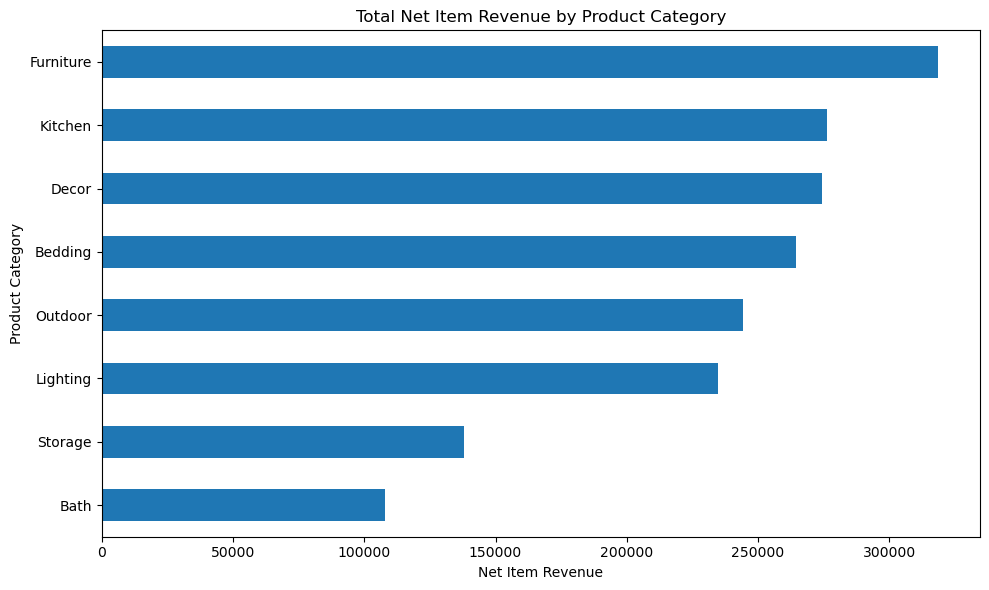

In [101]:
import matplotlib.pyplot as plt

category_sales["total_revenue"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Total Net Item Revenue by Product Category")
plt.xlabel("Net Item Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig(
    r"C:\Users\Goutham\Downloads\Wayfair Sales Analysis\charts\category_revenue.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [58]:
category_sales["profit_margin"] = (
    category_sales["estimated_profit"]
    / category_sales["total_revenue"]
) * 100

category_sales.round(2)

,total_revenue,estimated_profit,items_sold,profit_margin
category,,,,
Furniture,318593.13,147121.37,881,46.18
Kitchen,276103.06,130674.45,3630,47.33
Decor,274367.49,140489.80,3545,51.20
Bedding,264321.26,135375.14,2227,51.22
Outdoor,244097.30,121852.23,1635,49.92
Lighting,234583.07,111390.34,1516,47.48
Storage,137978.01,76700.44,2135,55.59
Bath,108077.68,50569.33,1976,46.79


step 3: Creating a Profit Margin Chart

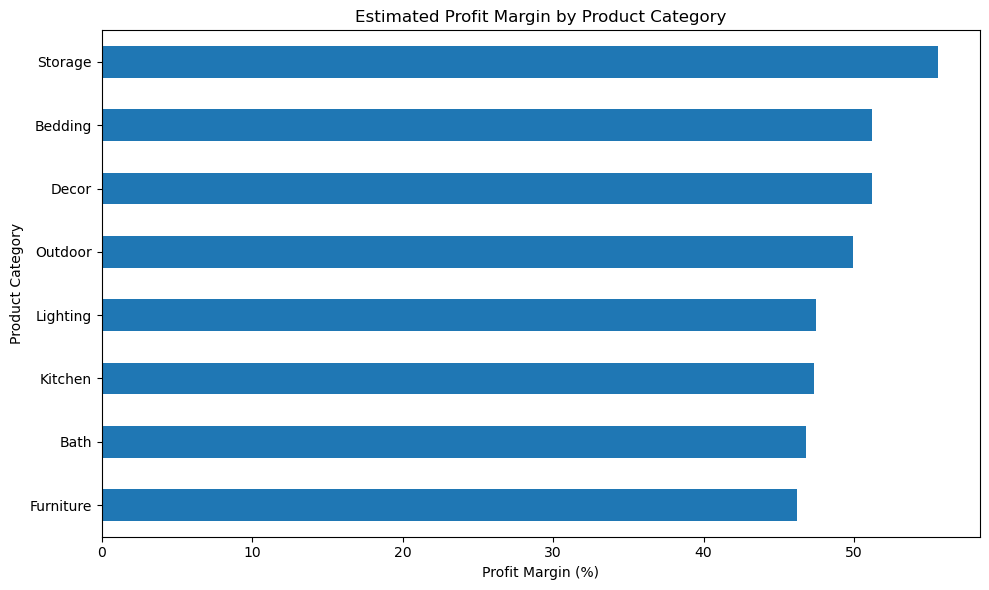

In [59]:
import matplotlib.pyplot as plt

category_sales["profit_margin"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Estimated Profit Margin by Product Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

Step 4: Calculate Monthly Revenue

In [60]:
# Extract the month from each order date
valid_completed_sales["order_month"] = (
    valid_completed_sales["order_date"].dt.to_period("M")
)

# Calculate revenue and estimated profit by month
monthly_sales = (
    valid_completed_sales
    .groupby("order_month")
    .agg(
        total_revenue=("net_item_revenue", "sum"),
        estimated_profit=("estimated_item_profit", "sum")
    )
    .reset_index()
)

monthly_sales.head()

,order_month,total_revenue,estimated_profit
0,2024-01,54107.56,26601.39
1,2024-02,62945.69,30484.95
2,2024-03,70885.83,33998.40
3,2024-04,64177.27,31230.12
4,2024-05,72246.90,34579.03


Step 5: Monthly Estimated Profit Trend

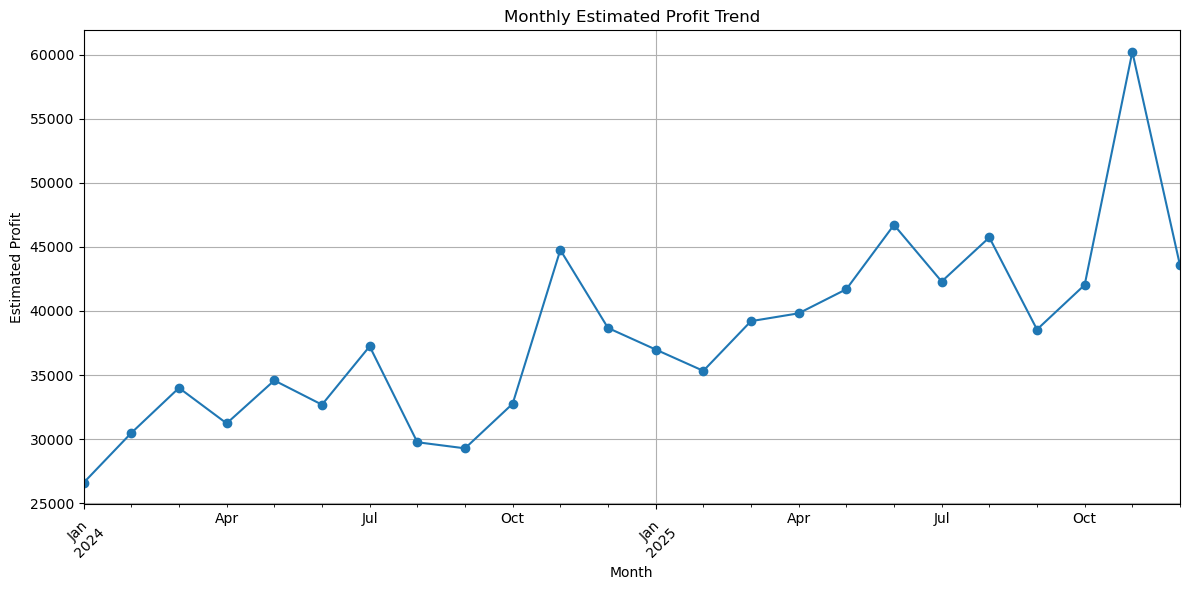

In [62]:
monthly_sales.plot(
    x="order_month",
    y="estimated_profit",
    kind="line",
    figsize=(12, 6),
    marker="o",
    legend=False
)

plt.title("Monthly Estimated Profit Trend")
plt.xlabel("Month")
plt.ylabel("Estimated Profit")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [64]:
monthly_sales.round(2)

,order_month,total_revenue,estimated_profit
0,2024-01,54107.56,26601.39
1,2024-02,62945.69,30484.95
2,2024-03,70885.83,33998.40
3,2024-04,64177.27,31230.12
4,2024-05,72246.90,34579.03
5,2024-06,66600.43,32687.37
6,2024-07,76264.13,37240.19
7,2024-08,61490.69,29759.69
8,2024-09,60028.03,29283.52
9,2024-10,66652.90,32761.67


Step 6: Comapring annual revenue and profit

In [65]:
monthly_sales["year"] = monthly_sales["order_month"].dt.year

yearly_sales = (
    monthly_sales
    .groupby("year")
    .agg(
        total_revenue=("total_revenue", "sum"),
        estimated_profit=("estimated_profit", "sum")
    )
)

yearly_sales.round(2)

,total_revenue,estimated_profit
year,,
2024,841136.33,402055.27
2025,1016984.67,512117.83


step 7: Calculating year over year growth

In [66]:
revenue_growth = (
    (yearly_sales.loc[2025, "total_revenue"]
     - yearly_sales.loc[2024, "total_revenue"])
    / yearly_sales.loc[2024, "total_revenue"]
) * 100

profit_growth = (
    (yearly_sales.loc[2025, "estimated_profit"]
     - yearly_sales.loc[2024, "estimated_profit"])
    / yearly_sales.loc[2024, "estimated_profit"]
) * 100

print(f"Revenue Growth: {revenue_growth:.2f}%")
print(f"Estimated Profit Growth: {profit_growth:.2f}%")

Revenue Growth: 20.91%
Estimated Profit Growth: 27.37%


step 8: Orders receiveing by monthly

In [67]:
monthly_orders = (
    orders[orders["status"] == "completed"]
    .assign(order_month=lambda df: df["order_date"].dt.to_period("M"))
    .groupby("order_month")
    .agg(total_orders=("order_id", "nunique"))
    .reset_index()
)

monthly_orders.head()

,order_month,total_orders
0,2024-01,263
1,2024-02,278
2,2024-03,296
3,2024-04,292
4,2024-05,307


step 9: Creating a monthly order trend chart

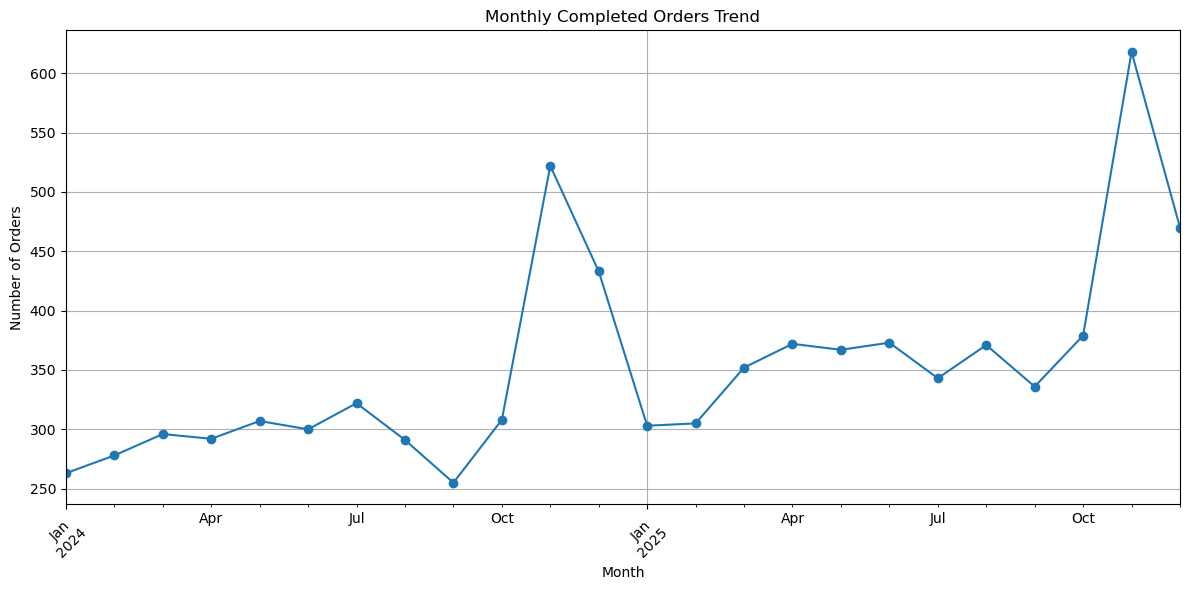

In [68]:
import matplotlib.pyplot as plt

monthly_orders.plot(
    x="order_month",
    y="total_orders",
    kind="line",
    figsize=(12, 6),
    marker="o",
    legend=False
)

plt.title("Monthly Completed Orders Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

step 10: Calculating monthly revenue per order

In [69]:
monthly_performance = pd.merge(
    monthly_sales,
    monthly_orders,
    on="order_month",
    how="left"
)

monthly_performance["revenue_per_order"] = (
    monthly_performance["total_revenue"]
    / monthly_performance["total_orders"]
)

monthly_performance.round(2).head()

,order_month,total_revenue,estimated_profit,year,total_orders,revenue_per_order
0,2024-01,54107.56,26601.39,2024,263,205.73
1,2024-02,62945.69,30484.95,2024,278,226.42
2,2024-03,70885.83,33998.40,2024,296,239.48
3,2024-04,64177.27,31230.12,2024,292,219.79
4,2024-05,72246.90,34579.03,2024,307,235.33


step 11: Comparing monthly revenue and order volume visually

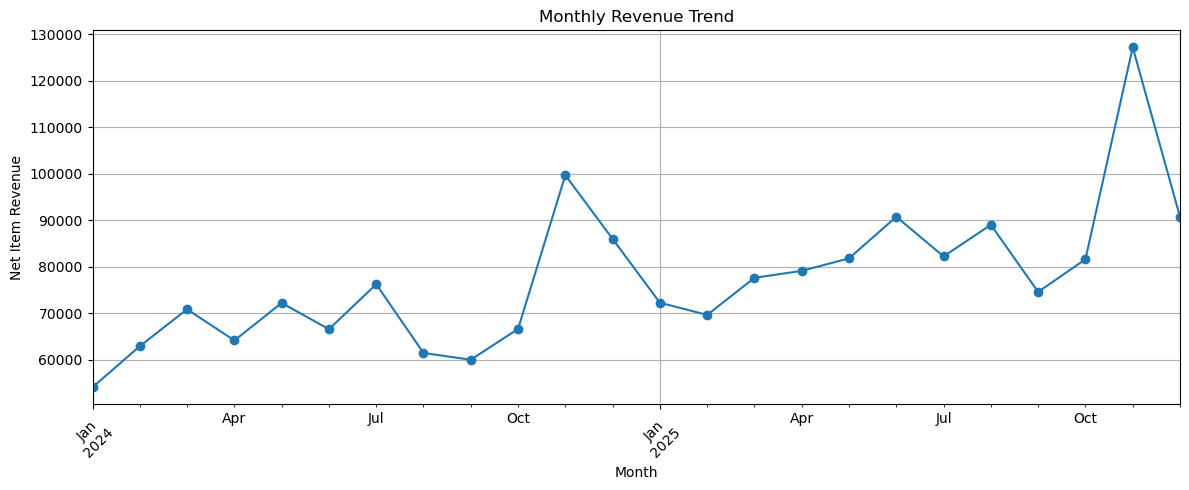

In [100]:
monthly_performance.plot(
    x="order_month",
    y="total_revenue",
    kind="line",
    figsize=(12, 5),
    marker="o",
    legend=False
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Net Item Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig(
    r"C:\Users\Goutham\Downloads\Wayfair Sales Analysis\charts\monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

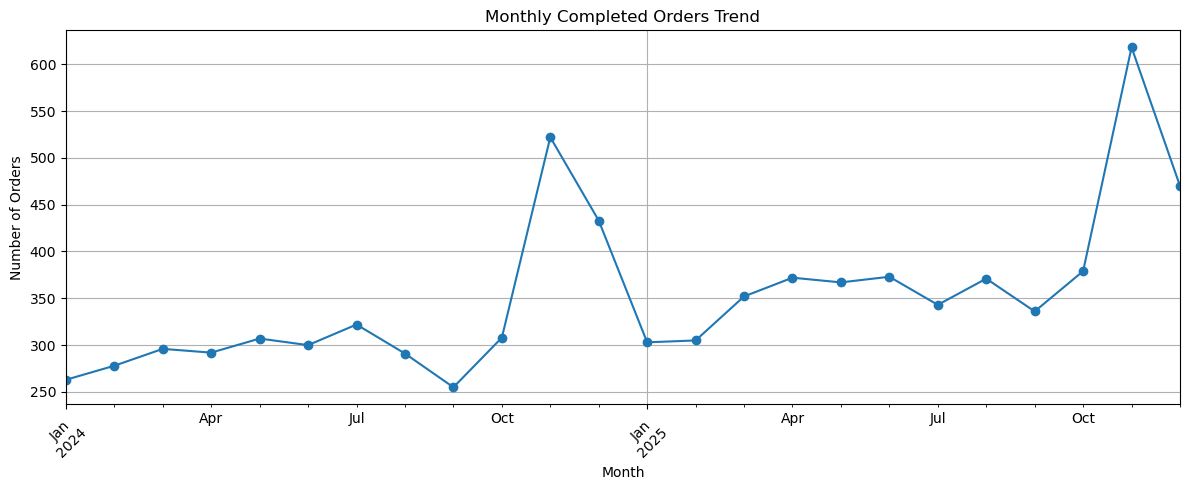

In [71]:
# order chart
monthly_performance.plot(
    x="order_month",
    y="total_orders",
    kind="line",
    figsize=(12, 5),
    marker="o",
    legend=False
)

plt.title("Monthly Completed Orders Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

step 12: Calculating yearly revenue per order

In [72]:
yearly_orders = (
    monthly_orders
    .assign(year=lambda df: df["order_month"].dt.year)
    .groupby("year")
    .agg(total_orders=("total_orders", "sum"))
)

yearly_performance = yearly_sales.join(yearly_orders)

yearly_performance["revenue_per_order"] = (
    yearly_performance["total_revenue"]
    / yearly_performance["total_orders"]
)

yearly_performance.round(2)

,total_revenue,estimated_profit,total_orders,revenue_per_order
year,,,,
2024,841136.33,402055.27,3867,217.52
2025,1016984.67,512117.83,4589,221.61


step 13: calculating growth rates 

In [73]:
order_growth = (
    (yearly_performance.loc[2025, "total_orders"]
     - yearly_performance.loc[2024, "total_orders"])
    / yearly_performance.loc[2024, "total_orders"]
) * 100

revenue_per_order_growth = (
    (yearly_performance.loc[2025, "revenue_per_order"]
     - yearly_performance.loc[2024, "revenue_per_order"])
    / yearly_performance.loc[2024, "revenue_per_order"]
) * 100

print(f"Completed Order Growth: {order_growth:.2f}%")
print(f"Revenue per Order Growth: {revenue_per_order_growth:.2f}%")

Completed Order Growth: 18.67%
Revenue per Order Growth: 1.88%


step 14: Calculating product-level performance

In [74]:
product_performance = (
    valid_completed_sales
    .groupby("product_name")
    .agg(
        total_revenue=("net_item_revenue", "sum"),
        estimated_profit=("estimated_item_profit", "sum"),
        quantity_sold=("quantity", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

product_performance.head(10).round(2)

,total_revenue,estimated_profit,quantity_sold
product_name,,,
Cotton Patio Chair,66566.91,29791.29,141
Classic Dining Chair Pair,51243.95,21842.93,66
Coastal Picture Frame Set,43702.80,24492.12,306
Ceramic Quilt,40953.19,20965.99,192
Bamboo Nightstand,40864.89,17278.29,76
Modern Wreath,40183.10,20619.70,290
Nordic Side Table,39316.68,21847.84,71
Marble Bookshelf,38595.66,16799.66,80
Classic Garland,38397.95,21635.49,286


step 15: Calculating estimated profit margins

In [75]:
product_performance["profit_margin"] = (
    product_performance["estimated_profit"]
    / product_performance["total_revenue"]
) * 100

product_performance.head(10).round(2)

,total_revenue,estimated_profit,quantity_sold,profit_margin
product_name,,,,
Cotton Patio Chair,66566.91,29791.29,141,44.75
Classic Dining Chair Pair,51243.95,21842.93,66,42.63
Coastal Picture Frame Set,43702.80,24492.12,306,56.04
Ceramic Quilt,40953.19,20965.99,192,51.20
Bamboo Nightstand,40864.89,17278.29,76,42.28
Modern Wreath,40183.10,20619.70,290,51.31
Nordic Side Table,39316.68,21847.84,71,55.57
Marble Bookshelf,38595.66,16799.66,80,43.53
Classic Garland,38397.95,21635.49,286,56.35


In [76]:
# HIghest margin products
top_margin_products = (
    product_performance
    .sort_values("profit_margin", ascending=False)
    .head(10)
)

top_margin_products.round(2)

,total_revenue,estimated_profit,quantity_sold,profit_margin
product_name,,,,
Linen Pendant Light,33498.49,19317.69,160,57.67
Coastal Closet System,26154.89,15078.09,224,57.65
Cotton Bath Mat,5107.34,2942.54,164,57.61
Stoneware Wall Mirror,30834.85,17744.63,253,57.55
Bamboo Bed Skirt,26590.69,15164.13,158,57.03
Bamboo Laundry Basket,4438.79,2522.45,246,56.83
Matte Black Utensil Set,10922.60,6176.66,249,56.55
Velvet String Lights,37883.96,21370.80,164,56.41
Classic Garland,38397.95,21635.49,286,56.35


In [77]:
# analysis of customer revenue
customer_performance = (
    valid_completed_sales
    .groupby("customer_id")
    .agg(
        total_revenue=("net_item_revenue", "sum"),
        estimated_profit=("estimated_item_profit", "sum"),
        total_items=("quantity", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

customer_performance.head(10).round(2)

,total_revenue,estimated_profit,total_items,total_orders
customer_id,,,,
3531,18735.34,9140.12,181,70
1552,16497.09,8030.75,152,73
1104,15729.91,7715.75,147,74
48,15517.57,7661.85,154,72
2821,15075.56,7473.98,125,65
3069,12145.35,5984.55,104,49
443,12087.78,5653.49,105,53
307,11651.96,5685.13,103,50
2577,10307.25,5038.78,106,54


In [78]:
# Analysis repeat customers versus one time customers
completed_orders = orders[orders["status"] == "completed"].copy()

customer_order_counts = (
    completed_orders
    .groupby("customer_id")
    .agg(total_orders=("order_id", "nunique"))
)

customer_order_counts.head()

,total_orders
customer_id,
2,1
4,1
5,6
6,2
7,1


In [79]:
# Classifying customers
customer_order_counts["customer_type"] = np.where(
    customer_order_counts["total_orders"] == 1,
    "One-time",
    "Repeat"
)

customer_order_counts.head()

,total_orders,customer_type
customer_id,,
2,1,One-time
4,1,One-time
5,6,Repeat
6,2,Repeat
7,1,One-time


In [81]:
# Counting each customer type
customer_type_counts = (
    customer_order_counts["customer_type"]
    .value_counts()
)

customer_type_counts

customer_type
Repeat      1318
One-time     729
Name: count, dtype: int64

In [82]:
customer_percentages = (
    customer_type_counts / customer_type_counts.sum()
) * 100

customer_summary = pd.DataFrame({
    "customer_count": customer_type_counts,
    "percentage": customer_percentages
})

customer_summary.round(2)

,customer_count,percentage
customer_type,,
Repeat,1318,64.39
One-time,729,35.61


In [83]:
# Analysing order statuses
order_status_summary = (
    orders["status"]
    .value_counts()
    .to_frame(name="order_count")
)

order_status_summary["percentage"] = (
    order_status_summary["order_count"] / len(orders)
) * 100

order_status_summary.round(2)

,order_count,percentage
status,,
completed,8456,91.84
returned,407,4.42
canceled,344,3.74


Step 16: Visualize order statuses


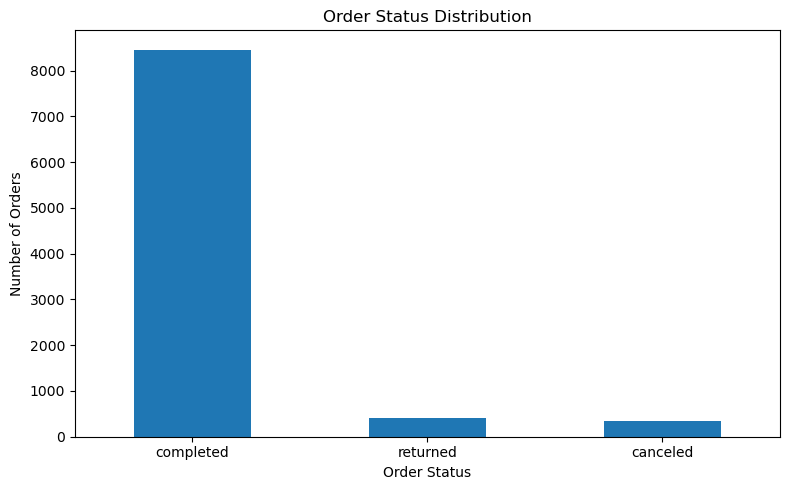

In [84]:
import matplotlib.pyplot as plt

order_status_summary["order_count"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [85]:
# understanding discount patterns
discount_summary = valid_completed_sales.agg(
    total_gross_amount=("gross_item_amount", "sum"),
    total_discount=("discount_amount", "sum"),
    net_revenue=("net_item_revenue", "sum"),
    estimated_profit=("estimated_item_profit", "sum")
)

discount_summary.round(2)

,gross_item_amount,discount_amount,net_item_revenue,estimated_item_profit
total_gross_amount,1902680.5,NaN,NaN,NaN
total_discount,NaN,44559.5,NaN,NaN
net_revenue,NaN,NaN,1858121.0,NaN
estimated_profit,NaN,NaN,NaN,914173.1


In [86]:
# analysis discounts by product category
discount_by_category = (
    valid_completed_sales
    .groupby("category")
    .agg(
        gross_revenue=("gross_item_amount", "sum"),
        total_discount=("discount_amount", "sum"),
        net_revenue=("net_item_revenue", "sum"),
        estimated_profit=("estimated_item_profit", "sum")
    )
)

discount_by_category["discount_rate"] = (
    discount_by_category["total_discount"]
    / discount_by_category["gross_revenue"]
) * 100

discount_by_category["profit_margin"] = (
    discount_by_category["estimated_profit"]
    / discount_by_category["net_revenue"]
) * 100

discount_by_category = discount_by_category.sort_values(
    "discount_rate", ascending=False
)

discount_by_category.round(2)

,gross_revenue,total_discount,net_revenue,estimated_profit,discount_rate,profit_margin
category,,,,,,
Decor,283110.75,8743.26,274367.49,140489.80,3.09,51.20
Kitchen,283271.30,7168.24,276103.06,130674.45,2.53,47.33
Bedding,271183.03,6861.77,264321.26,135375.14,2.53,51.22
Bath,110804.29,2726.61,108077.68,50569.33,2.46,46.79
Lighting,239981.49,5398.42,234583.07,111390.34,2.25,47.48
Storage,141045.60,3067.59,137978.01,76700.44,2.17,55.59
Furniture,325317.09,6723.96,318593.13,147121.37,2.07,46.18
Outdoor,247966.95,3869.65,244097.30,121852.23,1.56,49.92


step 17: creating discoun - rate chart

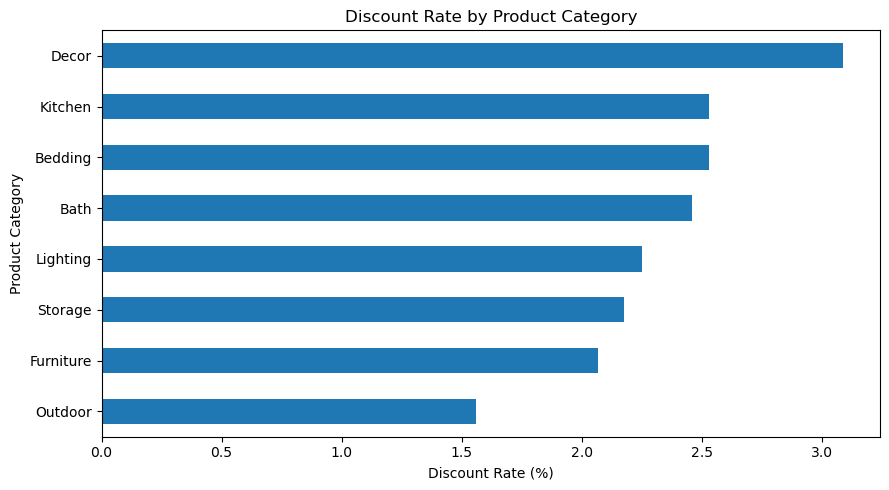

In [87]:
import matplotlib.pyplot as plt

discount_by_category["discount_rate"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Discount Rate by Product Category")
plt.xlabel("Discount Rate (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [88]:
completed_sales = sales[sales["status"] == "completed"].copy()

valid_completed_sales = completed_sales.dropna(
    subset=["unit_price"]
).copy()

In [91]:
# seasonality analysis
seasonality = (
    valid_completed_sales
    .assign(
        year=valid_completed_sales["order_date"].dt.year,
        month=valid_completed_sales["order_date"].dt.month,
        month_name=valid_completed_sales["order_date"].dt.strftime("%B")
    )
    .groupby(["year", "month", "month_name"])["net_item_revenue"]
    .sum()
    .reset_index()
    .groupby(["month", "month_name"])["net_item_revenue"]
    .mean()
    .reset_index(name="average_monthly_revenue")
    .sort_values("month")
)

display(seasonality)



,month,month_name,average_monthly_revenue
0,1,January,63202.735
1,2,February,66311.295
2,3,March,74269.520
3,4,April,71663.200
4,5,May,77043.755
5,6,June,78690.925
6,7,July,79261.420
7,8,August,75274.535
8,9,September,67325.300
9,10,October,74144.030


#step 18: Creating a seasonality chart






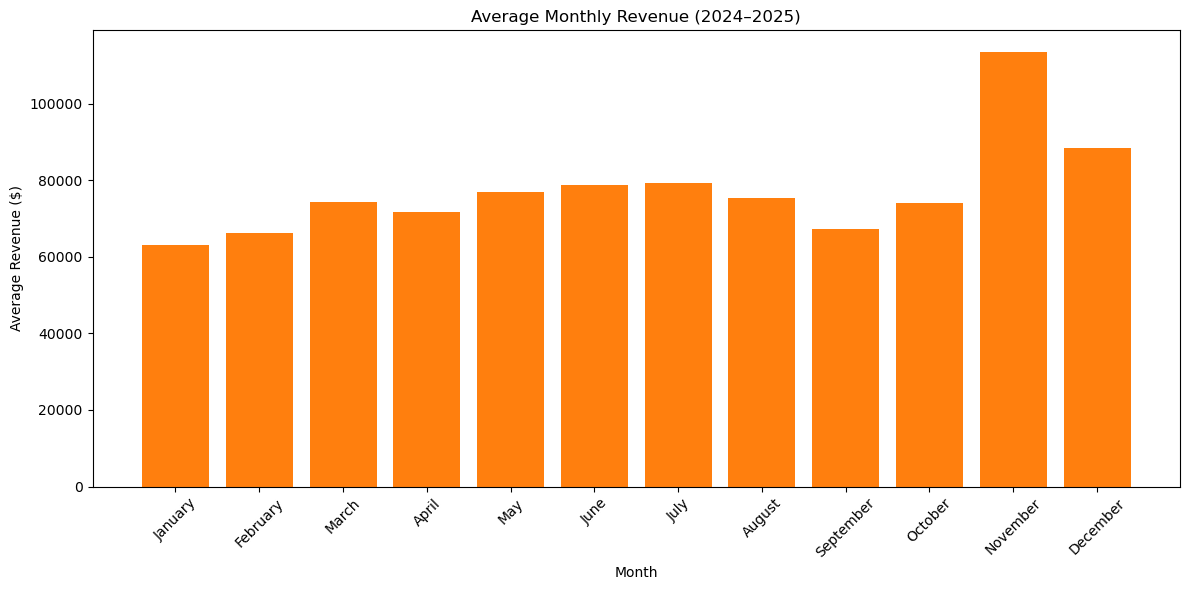

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    seasonality["month_name"],
    seasonality["average_monthly_revenue"]
)

plt.title("Average Monthly Revenue (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Average Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.bar( seasonality["month_name"], seasonality["average_monthly_revenue"])
plt.show()

In [94]:
# Analysis returns and cancellations by product category
status_by_category = (
    sales[sales["status"].isin(["returned", "canceled"])]
    .groupby(["category", "status"])
    .agg(
        order_items=("order_id", "count"),
        quantity=("quantity", "sum")
    )
    .reset_index()
    .sort_values(["status", "order_items"], ascending=[True, False])
)

display(status_by_category)



,category,status,order_items,quantity
8,Kitchen,canceled,119,154
4,Decor,canceled,116,151
0,Bath,canceled,77,93
2,Bedding,canceled,62,88
14,Storage,canceled,61,77
12,Outdoor,canceled,56,70
10,Lighting,canceled,37,43
6,Furniture,canceled,31,31
9,Kitchen,returned,139,174
5,Decor,returned,136,164


In [95]:
# Analysis average order value (AOV)
# Calculate revenue for each completed order
order_revenue = (
    valid_completed_sales
    .groupby("order_id")["net_item_revenue"]
    .sum()
    .reset_index(name="order_revenue")
)

# Calculate average order value
aov = order_revenue["order_revenue"].mean()

print(f"Average Order Value (AOV): ${aov:.2f}")
print(f"Number of orders included: {len(order_revenue)}")



Average Order Value (AOV): $221.28
Number of orders included: 8397


# Wayfair Sales Analysis — Executive Summary

## Project Overview

This project analyzes Wayfair sales data to understand revenue trends, product and category performance, customer purchasing behavior, and order outcomes. The analysis uses Python and Pandas to clean, combine, and analyze four datasets containing orders, order items, products, and customers.

## Key Findings

**1. Revenue increased in 2025.**
Net merchandise revenue from completed orders with valid item prices increased from $841,136.33 in 2024 to $1,016,984.67 in 2025, representing approximately **20.91% year-over-year growth**. Estimated item profit increased by 27.37%.

**2. Category performance varied.**
Furniture generated the highest category revenue at $318,593.13, while Kitchen had the highest quantity sold, with 3,630 items. Bath generated the lowest category revenue at $108,077.68. These differences show that revenue and sales volume vary by category.

**3. November was the strongest sales month.**
Average monthly revenue across 2024 and 2025 was highest in November at approximately $113,479.07. This suggests a possible seasonal sales peak, although additional years of data would be needed to confirm a consistent long-term pattern.

## Recommendations

**1. Investigate opportunities to improve lower-performing categories.**
Review Bath category pricing, product assortment, customer demand, and marketing performance to identify practical opportunities for improvement. Compare these results with category profit margins before deciding on changes.

**2. Prepare for potential seasonal demand.**
Use the November revenue peak to inform inventory planning and promotional scheduling. Validate the pattern with additional years of data before making major seasonal inventory commitments.

## Conclusion

The analysis identified year-over-year revenue growth, differences in category performance, and a November revenue peak. These findings can support better sales planning and category-level decisions. Revenue calculations exclude completed-order items with missing unit prices, and estimated item profit does not account for all business operating expenses.

In [97]:
import os

print(os.getcwd())

C:\Users\Goutham\Downloads\Wayfair Sales Analysis\notebooks


In [98]:
import os

chart_path = "../charts/monthly_seasonality.png"

print("Chart exists:", os.path.exists(chart_path))
print("Full path:", os.path.abspath(chart_path))

Chart exists: False
Full path: C:\Users\Goutham\Downloads\Wayfair Sales Analysis\charts\monthly_seasonality.png


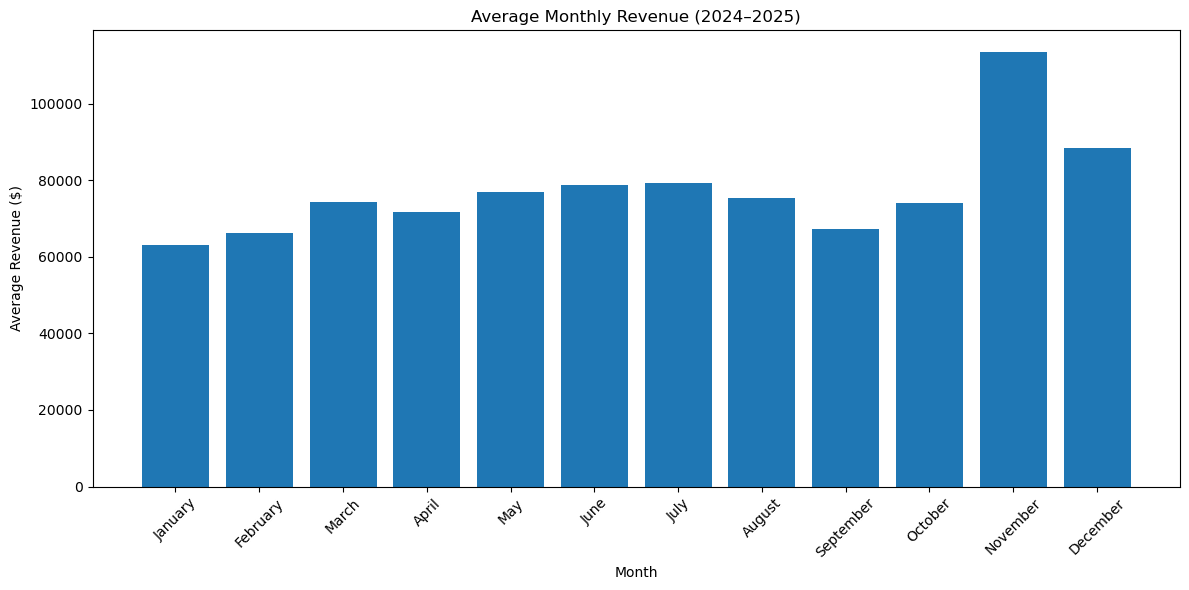

Chart saved: True
Location: C:\Users\Goutham\Downloads\Wayfair Sales Analysis\charts\monthly_seasonality.png


In [99]:
import os
import matplotlib.pyplot as plt

# Create the charts folder if it doesn't exist
charts_dir = r"C:\Users\Goutham\Downloads\Wayfair Sales Analysis\charts"
os.makedirs(charts_dir, exist_ok=True)

# Save the seasonality chart
plt.figure(figsize=(12, 6))
plt.bar(
    seasonality["month_name"],
    seasonality["average_monthly_revenue"]
)

plt.title("Average Monthly Revenue (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Average Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()

chart_file = os.path.join(charts_dir, "monthly_seasonality.png")
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", os.path.exists(chart_file))
print("Location:", chart_file)